# A bank queue

In Radiant: **Load example > Bank queue (waiting times)**.

## Question

> Customers arrive at a bank on average every 2 minutes (exponential times between arrivals) and service takes on average 3.5 minutes (exponential). With 2 tellers, how long do customers wait, how long is the line, and how often does someone wait more than 5 minutes? How does the average wait change with 1 to 4 tellers?

In [1]:
import pyrsm as rsm

Each row is a customer. `gap` is the time since the previous customer arrived and `service` the time a teller needs; both are **exponential** with a rate (the mean is 1 / rate). `queue_wait(gap, service, tellers)` works out, customer by customer, when a teller is free (first come, first served) and returns each customer's wait; `queue_length` returns how many customers are already waiting when a customer arrives. `in_bank[-1]` is the last customer (counting from the end, as in Python).

In [2]:
spec = {
    "name": "queue",
    "runs": 2000,
    "seed": 1234,
    "variables": [
        {"name": "tellers", "kind": "constant", "value": 2},
        {"name": "gap", "kind": "exponential", "rate": 0.5},
        {"name": "service", "kind": "exponential", "rate": "1 / 3.5"},
    ],
    "formulas": [
        "# minutes each customer waits before a teller is free",
        "wait = queue_wait(gap, service, tellers)",
        "# customers already waiting when a customer arrives",
        "line = queue_length(gap, service, tellers)",
        "in_bank = wait + service",
        "wait_5 = wait > 5",
        "utilization = sum(service) / (tellers * (sum(gap) + in_bank[-1]))",
    ],
}

In [3]:
sim = rsm.decide.simulate(spec)
sim.summary(dec=2)

Simulation
Simulations: 2,000
Random seed: 1234
Sim data   : queue
Constant   : tellers 2
Exponential: gap 0.5; service 1 / 3.5
Formulas   :
	# minutes each customer waits before a teller is free
	wait = queue_wait(gap, service, tellers)
	# customers already waiting when a customer arrives
	line = queue_length(gap, service, tellers)
	in_bank = wait + service
	wait_5 = wait > 5
	utilization = sum(service) / (tellers * (sum(gap) + in_bank[-1]))

Constants:
 tellers utilization
    2.00        0.86

Variables:
         n_obs  mean    sd  min  p25 median   p75   max
 gap     2,000  2.05  2.03 0.00 0.61   1.45  2.83 17.53
 service 2,000  3.53  3.63 0.00 1.01   2.40  4.86 32.19
 wait    2,000  9.51 10.03 0.00 0.79   6.27 15.29 49.89
 line    2,000  4.62  5.28 0.00 0.00   3.00  7.00 28.00
 in_bank 2,000 13.04 10.61 0.00 4.56  10.31 19.12 53.97

Logicals:
        TRUE (nr) TRUE (prop)
 wait_5     1,098        0.55


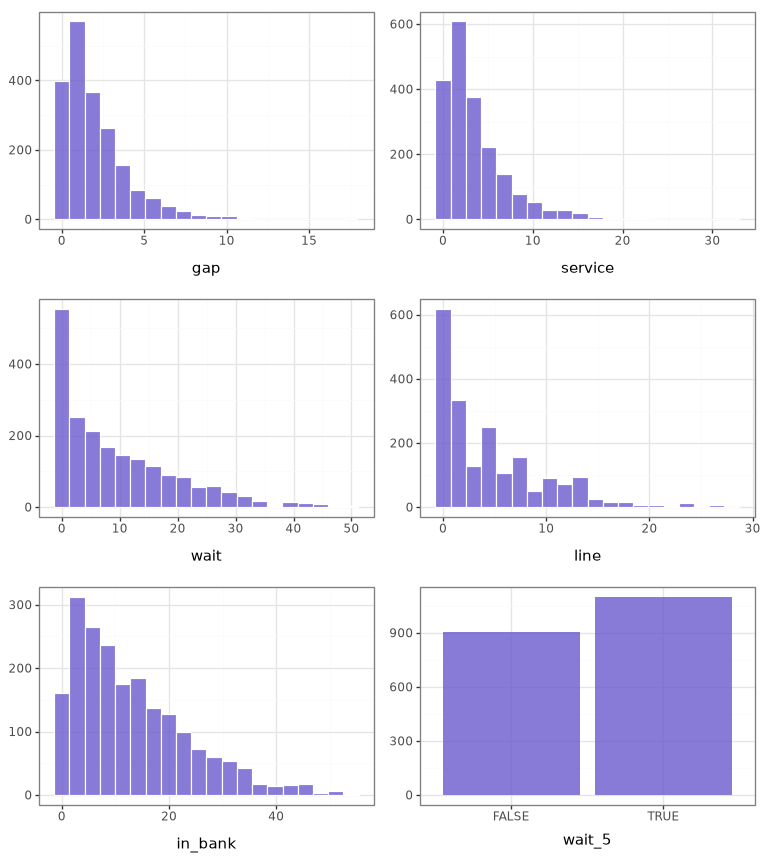

In [4]:
sim.plot()

## How many tellers? Grid search in a repeated simulation

With **group by Repeat**, a grid search replaces a constant of the simulation in each repetition: `tellers` from 1 to 4 gives four repetitions, each re-simulating the 2,000 customers. `mean` and `p95` summarise the waits of each repetition.

In [5]:
rep = rsm.decide.repeat_simulate(
    spec,
    reps=4,
    vars=["gap", "service"],
    sum_vars=["wait", "wait_5"],
    by="rep",
    fun=["mean", "p95"],
    grid=[
        {"name": "tellers", "min": 1, "max": 4, "step": 1},
    ],
    seed=1234,
)
rep.summary()

Repeated simulation
Simulations   : 2,000
Repetitions   : 4
Re-simulated  : gap, service
Group by      : Repeat
Function      : mean, p95
Random  seed  : 1234
Simulated data: queue
Grid search   : tellers 1 4 1

Variables:
             n_obs     mean         sd    min    p25  median      p75        max
 tellers         4   2.5000     1.2910 1.0000 1.7500  2.5000   3.2500     4.0000
 wait_mean       4 371.5143   733.6780 0.1396 0.6363  6.9613 377.8393 1,471.9949
 wait_5_mean     4   0.4188     0.4817 0.0025 0.0321  0.3375   0.7241     0.9975
 wait_p95        4 708.0765 1,389.5044 0.9828 3.7275 19.5557 723.9048 2,792.2117
 wait_5_p95      4   0.5000     0.5774 0.0000 0.0000  0.5000   1.0000     1.0000


In [6]:
rep.data

shape: (4, 6)
┌──────┬─────────┬─────────────┬─────────────┬─────────────┬────────────┐
│ .rep ┆ tellers ┆ wait_mean   ┆ wait_5_mean ┆ wait_p95    ┆ wait_5_p95 │
│ ---  ┆ ---     ┆ ---         ┆ ---         ┆ ---         ┆ ---        │
│ i64  ┆ f64     ┆ f64         ┆ f64         ┆ f64         ┆ f64        │
╞══════╪═════════╪═════════════╪═════════════╪═════════════╪════════════╡
│ 1    ┆ 1.0     ┆ 1471.994878 ┆ 0.9975      ┆ 2792.211729 ┆ 1.0        │
│ 2    ┆ 2.0     ┆ 13.120748   ┆ 0.633       ┆ 34.469124   ┆ 1.0        │
│ 3    ┆ 3.0     ┆ 0.801893    ┆ 0.042       ┆ 4.642332    ┆ 0.0        │
│ 4    ┆ 4.0     ┆ 0.139578    ┆ 0.0025      ┆ 0.982829    ┆ 0.0        │
└──────┴─────────┴─────────────┴─────────────┴─────────────┴────────────┘

With one teller service is slower than arrivals and the line keeps growing. Two tellers are busy about 86% of the time and most customers wait; a third teller cuts the average wait to under a minute.

The same wait can be written as a custom function (Lindley's recursion for one server) -- `queue_wait` does this for any number of servers:

In [7]:
from pyrsm.decide.simfuns import zeros


def wait_one(gap, service):
    w = zeros(len(gap))
    for i in range(1, len(gap)):
        w[i] = max(0, w[i - 1] + service[i - 1] - gap[i])
    return w


one = dict(spec, functions=[wait_one], formulas=["w1 = queue_wait(gap, service, 1)", "w2 = wait_one(gap, service)", "same = abs(w1 - w2) < 1e-9"])
rsm.decide.simulate(one).data["same"].all()

True